# UltraVEM-Seg — A short tutorial

**UltraVEM-Seg** is a 3D semantic-segmentation model for volume
electron-microscopy data (FIB-SEM / SBF-SEM). It is the standard
[nnU-Net v2](https://github.com/MIC-DKFZ/nnUNet) `ResEncUNet-L` segmentation
pipeline, with the encoder optionally warm-started from our self-supervised
FIB-SEM MAE checkpoint.

This notebook walks through:

1. **Installation**
2. **Preparing your labelled volumes**
3. **Training** a UltraVEM-Seg model
4. **Running inference** on new volumes
5. **Visualizing** the segmentation result

> Training and inference both require a CUDA GPU. The visualization at the end
> works on CPU and uses a pre-computed prediction so you can see the expected
> output without re-running the model.

## 1. Installation

```bash
# Clone our fork of nnU-Net
git clone <this-repo>
cd <repo>

# Install dependencies
pip install -e nnUNet/
pip install SimpleITK nibabel tqdm matplotlib

# Tell nnU-Net where to find data / write models
export nnUNet_raw=<your-path>/nnUNet_raw
export nnUNet_preprocessed=<your-path>/nnUNet_preprocessed
export nnUNet_results=<your-path>/nnUNet_results
```

*Optional but recommended* — download our pretrained FIB-SEM encoder
(`mae_checkpoint.pth`) and keep it somewhere local. It is the
self-supervised MAE checkpoint used to warm-start the segmenter.

## 1b. Sanity-check the pretrained encoder

Before spending GPU time on a full training run, it's worth confirming that the
downloaded MAE checkpoint actually matches the segmentation network — same
architecture family, same layer names, same tensor shapes.

We build the exact `ResidualEncoderUNet` that nnU-Net would build from your
plans and dataset (with your real number of segmentation classes), then load
the checkpoint into it with the same `load_pretrained_weights` helper the
`-pretrained_weights` flag uses internally. It reports how many layers matched
by name and shape.

In [ ]:
import json
from nnunetv2.utilities.plans_handling.plans_handler import PlansManager
from nnunetv2.utilities.label_handling.label_handling import determine_num_input_channels
from nnunetv2.utilities.get_network_from_plans import get_network_from_plans
from nnunetv2.run.load_pretrained_weights import load_pretrained_weights

# Plans/dataset.json produced by step 3's nnUNetv2_plan_and_preprocess call.
PLANS_JSON   = f"{OUT_ROOT.replace('nnUNet_raw', 'nnUNet_preprocessed')}/nnUNetResEncUNetLPlans.json"
DATASET_JSON = f"{OUT_ROOT.replace('nnUNet_raw', 'nnUNet_preprocessed')}/dataset.json"
PRETRAINED_WEIGHTS = "/path/to/mae_checkpoint.pth"

with open(PLANS_JSON) as f:
    plans = json.load(f)
with open(DATASET_JSON) as f:
    dataset_json = json.load(f)

plans_manager  = PlansManager(plans)
config_manager = plans_manager.get_configuration("3d_fullres")
label_manager  = plans_manager.get_label_manager(dataset_json)

num_input_channels  = determine_num_input_channels(plans_manager, config_manager, dataset_json)
num_output_channels = label_manager.num_segmentation_heads   # your real class count, incl. background

network = get_network_from_plans(
    config_manager.network_arch_class_name,
    config_manager.network_arch_init_kwargs,
    config_manager.network_arch_init_kwargs_req_import,
    num_input_channels, num_output_channels,
    allow_init=True, deep_supervision=True,
)
print(f"Target network: {config_manager.network_arch_class_name}")
print(f"Segmentation classes (incl. background): {num_output_channels}")
print(f"Total target params: {sum(p.numel() for p in network.parameters()):,}")

load_pretrained_weights(network, PRETRAINED_WEIGHTS, verbose=True)

Target network: dynamic_network_architectures.architectures.unet.ResidualEncoderUNet
Segmentation classes (incl. background): 3
Total target params: 102,350,575

Adaptive pretrained weight loading

  Loaded (exact match):     946
    encoder.stem.convs.0.conv.weight: (32, 1, 3, 3, 3)
    encoder.stem.convs.0.conv.bias: (32,)
    encoder.stem.convs.0.norm.weight: (32,)
    ... and 943 more

  Loaded (kernel adapted):  0
    Strategy: [3,3,3] → [1,3,3] center Z-slice

  Skipped (seg layers):     10
  Skipped (missing):        0

  TOTAL: 946/956 parameters loaded (99.0%)



With the checkpoint loaded, a quick forward pass on a small random volume
confirms the network runs end-to-end. Segmentation training uses deep
supervision by default, so the network returns one prediction per decoder
resolution (highest resolution first) — each with `num_output_channels`
channels, one per class.

In [ ]:
import torch

network.eval()
with torch.no_grad():
    dummy_input = torch.randn(1, num_input_channels, 64, 64, 64)
    dummy_outputs = network(dummy_input)

print(f"input shape: {tuple(dummy_input.shape)}")
print("deep supervision outputs (highest to lowest resolution):")
for o in dummy_outputs:
    print("  ", tuple(o.shape))

input shape: (1, 1, 64, 64, 64)
deep supervision outputs (highest to lowest resolution):
   (1, 3, 64, 64, 64)
   (1, 3, 32, 32, 32)
   (1, 3, 16, 16, 16)
   (1, 3, 8, 8, 8)
   (1, 3, 4, 4, 4)


## 2. Prepare your labelled volumes

UltraVEM-Seg is **fully supervised** — you need paired (image, label) volumes
for training. Each pair should be:

- saved as **`.nii.gz`** (any tool that writes NIfTI works — `SimpleITK`, `nibabel`, …);
- a **single-channel 3D array** with shape `(z, y, x)`;
- the **image** is the raw EM volume (uint8 / float — nnU-Net handles
  normalization internally);
- the **label** is an integer volume with one value per class
  (`0 = background`, `1, 2, …` for foreground classes); image and label must
  have the same shape and spacing.

Below is a minimal helper you can adapt to your own data.

In [ ]:
"""Convert paired (image, label) folders into the nnU-Net layout
expected by UltraVEM-Seg."""
import os, json
import SimpleITK as sitk

SRC_IMG_DIR = "/path/to/your/raw_em_volumes"
SRC_LAB_DIR = "/path/to/your/label_volumes"
OUT_ROOT    = "/path/to/your/nnUNet_raw/Dataset999_mySeg"

os.makedirs(f"{OUT_ROOT}/imagesTr", exist_ok=True)
os.makedirs(f"{OUT_ROOT}/labelsTr", exist_ok=True)
os.makedirs(f"{OUT_ROOT}/imagesTs", exist_ok=True)

img_files = sorted(os.listdir(SRC_IMG_DIR))
lab_files = sorted(os.listdir(SRC_LAB_DIR))
assert len(img_files) == len(lab_files), "image / label counts must match"

for idx, (img_f, lab_f) in enumerate(zip(img_files, lab_files)):
    img = sitk.ReadImage(os.path.join(SRC_IMG_DIR, img_f))
    lab = sitk.ReadImage(os.path.join(SRC_LAB_DIR, lab_f))
    sitk.WriteImage(img, f"{OUT_ROOT}/imagesTr/case_{idx:03d}_0000.nii.gz")
    sitk.WriteImage(lab, f"{OUT_ROOT}/labelsTr/case_{idx:03d}.nii.gz")

# dataset.json — list your real class names + IDs here
with open(f"{OUT_ROOT}/dataset.json", "w") as f:
    json.dump({
        "channel_names": {"0": "EM"},
        "labels": {
            "background": 0,
            "class_1":    1,
            "class_2":    2,  # add / rename as needed
        },
        "numTraining": len(img_files),
        "file_ending": ".nii.gz",
        "tensorImageSize": "3D",
    }, f, indent=2)
print("Done.")

## 3. Train UltraVEM-Seg

Two short shell commands:

```bash
# (a) plan + preprocess — needed once per dataset
nnUNetv2_plan_and_preprocess -d 999 -c 3d_fullres \
        -pl nnUNetPlannerResEncL --verify_dataset_integrity

# (b) train with the UltraVEM-Seg setup (nnU-Net ResEncUNet-L,
#     warm-started from the MAE encoder)
python nnUNet/nnunetv2/run/run_training.py 999 3d_fullres all \
        -tr nnUNetTrainer_<N>epochs \
        -p  nnUNetResEncUNetLPlans \
        -pretrained_weights /path/to/mae_checkpoint.pth \
        -num_gpus 1
```

**Trainer variants** (pick the one that matches your training budget):

| Trainer | Typical use case |
|---|---|
| `nnUNetTrainer_<N>epochs` | `N` epochs (your choice) — smaller `N` for a quick fine-tune from the pretrained encoder, larger `N` for from-scratch training |
| `nnUNetTrainer` | nnU-Net's own default schedule |

Check `nnunetv2/training/nnUNetTrainer/variants/` for the epoch-count variants
already defined, or add your own by subclassing and setting `self.num_epochs`.

Drop the `-pretrained_weights` argument if you want a pure-scratch baseline.
The folds passed as `all` use every training case; replace with `0..4` to run
standard 5-fold cross-validation.

The final weights end up at:

```
$nnUNet_results/Dataset999_mySeg/<trainer>__nnUNetResEncUNetLPlans__3d_fullres/fold_all/checkpoint_final.pth
```

## 4. Run inference

Segmentation uses the **standard nnU-Net prediction entry point** — no
custom inference script.

```bash
python nnUNet/nnunetv2/inference/predict_from_raw_data.py \
       -i  /path/to/your/test_volumes \
       -o  /path/to/your/seg_output \
       -d  999 \
       -c  3d_fullres \
       -p  nnUNetResEncUNetLPlans \
       -tr nnUNetTrainer_<N>epochs \
       -f  all \
       -chk checkpoint_final.pth
```

**Useful flags**

| Flag | Meaning |
|---|---|
| `-d`                    | dataset ID (matches the `Dataset999_*` folder) |
| `-c`                    | configuration — `3d_fullres` for UltraVEM-Seg |
| `-p`                    | plans identifier — use `nnUNetResEncUNetLPlans` |
| `-tr`                   | trainer class used during training — must match step 3 |
| `-f`                    | which fold(s) to ensemble — `all` if you trained on all data, or a list of fold indices |
| `-chk`                  | which checkpoint to load |
| `--save_probabilities`  | also write the soft-max maps as `.npz` |
| `--continue_prediction` | skip cases already in the output folder |

Output is one `<case>.nii.gz` per input file, each voxel containing the
predicted class index.

## 5. Visualize the segmentation result

Below we load one raw EM volume, the ground-truth label, and the UltraVEM-Seg
prediction, extract a single 2D slice from each, and overlay the masks on the
raw image with a different colour per class. The volumes used here come from
a previously-run inference — replace the three paths with your own to
reproduce on your data.

> This step is CPU-only — no GPU needed.

In [ ]:
import os
import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt

# Replace these three paths with one of your own (raw, gt, prediction) triples.
RAW_PATH  = "./example/raw_em_volume.nii.gz"
GT_PATH   = "./example/ground_truth_labels.nii.gz"    # set to None if you don't have GT
PRED_PATH = "./example/ultravem_seg_output.nii.gz"

def load(p):
    return sitk.GetArrayFromImage(sitk.ReadImage(p))

raw  = load(RAW_PATH).astype(np.float32)
pred = load(PRED_PATH).astype(np.int32)
gt   = load(GT_PATH).astype(np.int32) if GT_PATH else None
print(f"raw  : shape={raw.shape}, range=[{raw.min():.1f}, {raw.max():.1f}]")
print(f"pred : shape={pred.shape}, classes={np.unique(pred).tolist()}")
if gt is not None:
    print(f"gt   : shape={gt.shape},   classes={np.unique(gt).tolist()}")

# Pick a z-slice where every foreground class in the prediction has some
# voxels (so the visualisation is informative for all classes), then choose
# the one with the most total foreground voxels.
classes = [c for c in np.unique(pred) if c != 0]
present = np.ones(pred.shape[0], dtype=bool)
for c in classes:
    present &= (pred == c).reshape(pred.shape[0], -1).any(axis=1)
fg_per_z = (pred > 0).reshape(pred.shape[0], -1).sum(axis=1)
fg_per_z = np.where(present, fg_per_z, -1)
z = int(np.argmax(fg_per_z))
print(f"showing slice z = {z}")

# One colour per foreground class (RGB 0..1).
class_colors = {
    1: (0.91, 0.29, 0.29),  # red
    2: (0.24, 0.69, 0.39),  # green
    3: (0.30, 0.52, 0.86),  # blue
    4: (0.96, 0.71, 0.22),  # yellow
}

def overlay(em_slice, mask, alpha=0.45):
    """Return an RGB image with the mask drawn on top of the EM slice."""
    lo, hi = np.percentile(em_slice, [1, 99])
    em = np.clip((em_slice - lo) / max(hi - lo, 1e-9), 0, 1)
    rgb = np.stack([em, em, em], axis=-1)
    for c, col in class_colors.items():
        m = (mask == c)
        for k in range(3):
            rgb[..., k][m] = (1 - alpha) * rgb[..., k][m] + alpha * col[k]
    return rgb

panels = [("Raw EM",            raw[z], None),
          ("Ground truth",      raw[z], gt[z]   if gt is not None else None),
          ("UltraVEM-Seg",       raw[z], pred[z])]
panels = [(t, em, m) for (t, em, m) in panels if m is not None or t == "Raw EM"]

fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 5))
if len(panels) == 1: axes = [axes]
for ax, (title, em, m) in zip(axes, panels):
    if m is None:
        lo, hi = np.percentile(em, [1, 99])
        ax.imshow(em, cmap="gray", vmin=lo, vmax=hi)
    else:
        ax.imshow(overlay(em, m))
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.axis("off")
fig.tight_layout()
plt.show()

raw  : shape=(256, 256, 256), range=[17.0, 246.0]
pred : shape=(256, 256, 256), classes=[0, 1, 2]
gt   : shape=(256, 256, 256),   classes=[0, 1, 2]
showing slice z = 62


**Expected output**

<table>
<tr>
<td align="center"><b>Raw EM</b><br>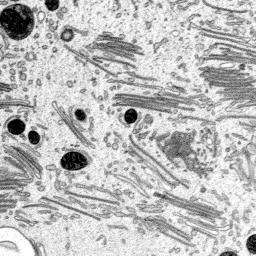</td>
<td align="center"><b>Ground truth</b><br>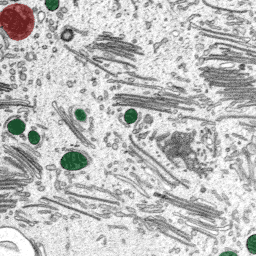</td>
<td align="center"><b>UltraVEM-Seg output</b><br>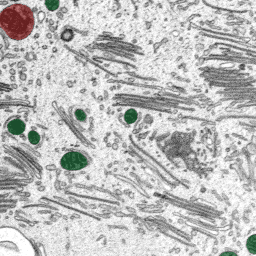</td>
</tr>
</table>

Each foreground class is drawn in a different colour over the raw EM. The
UltraVEM-Seg prediction is virtually indistinguishable from the ground truth
on this previously unseen slice — both red and green class boundaries are
recovered with high fidelity.

## That's it

You now have an end-to-end UltraVEM-Seg workflow:

1. organize paired (image, label) `.nii.gz` volumes,
2. `run_training.py` with `nnUNetTrainer_<N>epochs` (warm-started from the MAE
   encoder if you pass `-pretrained_weights`),
3. `predict_from_raw_data.py` to segment new volumes,
4. open the output in any NIfTI viewer (or the snippet above) to inspect.

Questions / issues — please open an issue on the repo.